In [10]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image
import tensorflow as tf

In [11]:
from datasets import load_dataset
ds = load_dataset("timm/amazon-from-space", split="train")

print(ds)
print(ds[0])

Ignoring part of dataset_info from the dataset card: The `splits` field in YAML is malformed or missing the name/num_examples/num_bytes fields
Ignoring part of dataset_info from the dataset card: The `splits` field in YAML is malformed or missing the name/num_examples/num_bytes fields


Dataset({
    features: ['image', 'labels', 'label_names', 'image_id', 'fold'],
    num_rows: 36431
})
{'image': <PIL.JpegImagePlugin.JpegImageFile image mode=CMYK size=256x256 at 0x7E2DDC889650>, 'labels': [10, 12], 'label_names': ['haze', 'primary'], 'image_id': 'train_0', 'fold': 5}


                label  count
1             primary  33762
3               clear  25588
2         agriculture  11083
6                road   7263
4               water   6670
10      partly_cloudy   6535
7         cultivation   4093
5          habitation   3294
0                haze   2427
9              cloudy   1880
12        bare_ground    775
15  selective_logging    306
13     artisinal_mine    305
14           blooming    298
8          slash_burn    188
16          blow_down     92
11  conventional_mine     90


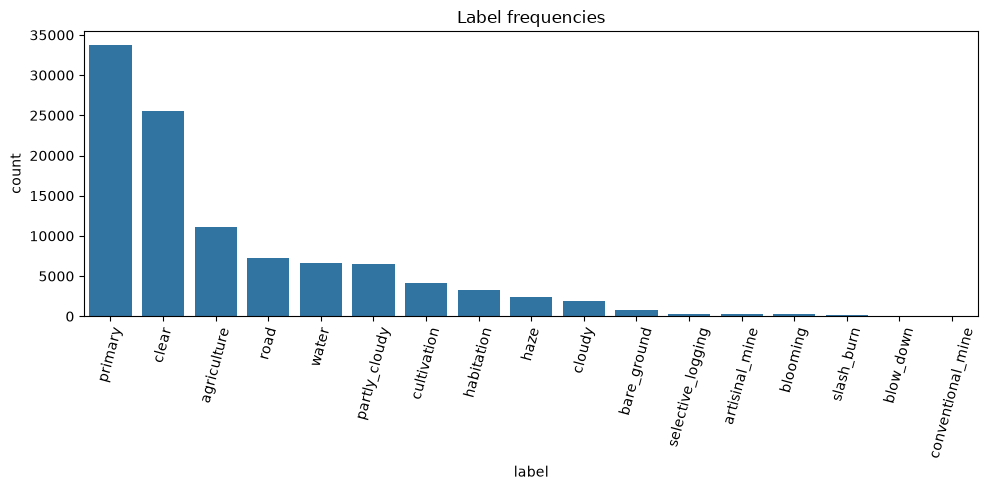

In [12]:
from collections import Counter

labelCounts = Counter()
for row in ds:
    labelCounts.update(row["label_names"])

countsDf = pd.DataFrame(labelCounts.items(), columns=["label", "count"]).sort_values("count", ascending=False)
print(countsDf)

plt.figure(figsize=(10, 5))
sns.barplot(data=countsDf, x="label", y="count")
plt.xticks(rotation=75)
plt.title("Label frequencies")
plt.tight_layout()
plt.show()

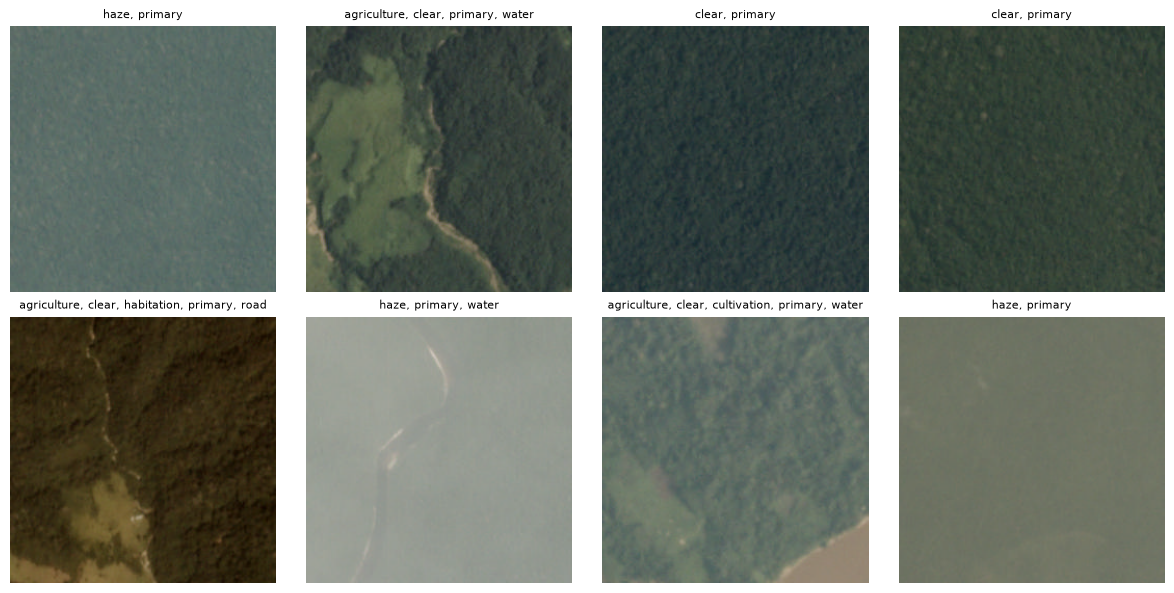

In [13]:
fig, axes = plt.subplots(2, 4, figsize=(12, 6))
for ax, i in zip(axes.flat, range(8)):
    row = ds[i]
    ax.imshow(row["image"].convert("RGB"))
    ax.set_title(", ".join(row["label_names"]), fontsize=8)
    ax.axis("off")
plt.tight_layout()
plt.show()